In [1]:
#Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
import numpy as np
%matplotlib inline
from sklearn import datasets, linear_model
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

In [2]:


# # Assuming 'your_data.xlsx' is the Excel file containing your data
# df = pd.read_excel('bee_db.xlsx', parse_dates=['datetime'])

# # Replace commas with dots in numeric columns for proper parsing
# numeric_columns = ['temperature', 'humidity', 'weight', 'filesize', 'workers', 'drones', 'ratio', 'total']
# df[numeric_columns] = df[numeric_columns].replace(',', '.', regex=True)

# # Convert numeric columns to appropriate data types
# df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors='coerce')

# # Save the result to a new CSV file
# df.to_csv('converted_data.csv', index=False)



In [3]:
#Were going to use the newly created bee data base to do some data magic!
dataset = pd.read_csv('bee_data.csv') #tourisme index_col='datetime'
dataset.head(10) #shows the first 10 columns of the dataframe

#Now we have created a nice & simple oversight of our data(frame)

,datetime,temperature,humidity,weight,filesize,workers,drones,ratio,total
0,2023-04-17 10:00:00,88.70,47.0,0.0,30960338,8,0,0.0,8
1,2023-04-17 12:00:00,88.70,49.8,0.0,30199021,18,0,0.0,18
2,2023-04-17 14:00:00,87.98,39.6,0.0,6214516,2,0,0.0,2
3,2023-04-17 16:00:00,87.56,43.0,0.0,61036,0,0,0.0,0
4,2023-04-17 18:00:00,87.14,46.4,0.0,59631,0,0,0.0,0
5,2023-04-17 20:00:00,86.72,49.8,0.0,60209,0,0,0.0,0
6,2023-04-18 08:00:00,89.96,45.3,0.0,57249447,18,0,0.0,18
7,2023-04-18 10:00:00,91.76,49.0,0.0,62443542,19,0,0.0,19
8,2023-04-18 12:00:00,92.39,47.5,0.0,41671100,7,0,0.0,7
9,2023-04-18 14:00:00,93.02,46.0,0.0,20154931,9,0,0.0,9


In [4]:
#Our data is recorded every 2 hours and loged in the rows as such, this creates weird & messy graphs, let's make it daily using resampling!

# Read the dataset from the CSV file
dataset = pd.read_csv('bee_data.csv', index_col='datetime')

# Convert the 'datetime' column to datetime type if it's not already
dataset.index = pd.to_datetime(dataset.index)

# Resample to daily frequency and aggregate using sum
daily_data = dataset.resample('D').sum()

print("Original DataFrame:")
print(dataset.head(2))
print("\nDaily aggregated DataFrame:")
print(daily_data.head(2))


Original DataFrame:
                     temperature  humidity  weight  filesize  workers  drones  \
datetime                                                                        
2023-04-17 10:00:00         88.7      47.0     0.0  30960338        8       0   
2023-04-17 12:00:00         88.7      49.8     0.0  30199021       18       0   

                     ratio  total  
datetime                           
2023-04-17 10:00:00    0.0      8  
2023-04-17 12:00:00    0.0     18  

Daily aggregated DataFrame:
            temperature  humidity  weight   filesize  workers  drones  ratio  \
datetime                                                                       
2023-04-17       526.80     275.6     0.0   67554751       28       0    0.0   
2023-04-18       367.13     187.8     0.0  181519020       53       0    0.0   

            total  
datetime           
2023-04-17     28  
2023-04-18     53  


In [5]:
#removing columns
daily_backup = daily_data
daily_data.drop(columns=['total', 'ratio'])


,temperature,humidity,weight,filesize,workers,drones
datetime,,,,,,
2023-04-17,526.80,275.60,0.000000,67554751,28,0
2023-04-18,367.13,187.80,0.000000,181519020,53,0
2023-04-19,643.94,360.10,0.001240,249608995,77,1
2023-04-20,630.80,349.10,0.003027,67360526,31,0
2023-04-21,347.78,184.95,0.002333,108699349,48,2
...,...,...,...,...,...,...
2023-10-24,562.22,282.70,0.004379,64252263,40,0
2023-10-25,545.48,265.20,0.002466,21282469,7,0
2023-10-26,522.44,291.10,0.000072,31581855,8,0


In [6]:
#Do you notice anything strange?
#If you look carefully then you see that aside from the workers and drones we also took the sum of the temperature and humidity, which is now of course wrong.
#We fix this by taking the mean of those values from all of those two hours put together.

# let's try again!
# Read the dataset from the CSV file

dataset = pd.read_csv('bee_data.csv', index_col='datetime')

# Convert the 'datetime' column to datetime type if it's not already
dataset.index = pd.to_datetime(dataset.index)

# Define aggregation functions for each column
aggregation = {
    'temperature': 'mean', # Take mean instead of sum
    'humidity': 'mean',  # Take mean instead of sum
    'weight': 'last', # take last weight change of the day which is kind of like taking the sum but without getting NaN values
    'filesize': 'sum',
    'workers': 'sum',
    'drones': 'sum',
}

# Resample to daily frequency and aggregate with different functions
daily_data = dataset.resample('D').agg(aggregation)
#daily_data['weight_change'] = dataset['weight'] #readding weight
daily_data['weight_change'] = daily_data['weight']
daily_data.drop(columns=['weight'], inplace=True)
# Use the cumulative sum of weight for a more accurate result then just using sum:
#daily_data['weight_cumsum'] = daily_data['weight'].cumsum()


print("Original DataFrame:")
print(dataset.head(2))
print("\nDaily aggregated DataFrame:")
print(daily_data.head(2))


Original DataFrame:
                     temperature  humidity  weight  filesize  workers  drones  \
datetime                                                                        
2023-04-17 10:00:00         88.7      47.0     0.0  30960338        8       0   
2023-04-17 12:00:00         88.7      49.8     0.0  30199021       18       0   

                     ratio  total  
datetime                           
2023-04-17 10:00:00    0.0      8  
2023-04-17 12:00:00    0.0     18  

Daily aggregated DataFrame:
            temperature   humidity   filesize  workers  drones  weight_change
datetime                                                                     
2023-04-17      87.8000  45.933333   67554751       28       0            0.0
2023-04-18      91.7825  46.950000  181519020       53       0            0.0


In [7]:
daily_data.head(10)


,temperature,humidity,filesize,workers,drones,weight_change
datetime,,,,,,
2023-04-17,87.800000,45.933333,67554751,28,0,0.000000
2023-04-18,91.782500,46.950000,181519020,53,0,0.000000
2023-04-19,91.991429,51.442857,249608995,77,1,0.000000
2023-04-20,90.114286,49.871429,67360526,31,0,0.002250
2023-04-21,86.945000,46.237500,108699349,48,2,0.000000
2023-04-22,90.885714,49.885714,138937170,66,0,0.000111
2023-04-23,91.297143,49.335714,128830793,58,0,0.002333
2023-04-24,89.188571,46.242857,97215486,42,0,0.000000
2023-04-25,87.517143,45.314286,121026015,43,1,0.000000


In [8]:
dataset.head(10)

,temperature,humidity,weight,filesize,workers,drones,ratio,total
datetime,,,,,,,,
2023-04-17 10:00:00,88.70,47.0,0.0,30960338,8,0,0.0,8
2023-04-17 12:00:00,88.70,49.8,0.0,30199021,18,0,0.0,18
2023-04-17 14:00:00,87.98,39.6,0.0,6214516,2,0,0.0,2
2023-04-17 16:00:00,87.56,43.0,0.0,61036,0,0,0.0,0
2023-04-17 18:00:00,87.14,46.4,0.0,59631,0,0,0.0,0
2023-04-17 20:00:00,86.72,49.8,0.0,60209,0,0,0.0,0
2023-04-18 08:00:00,89.96,45.3,0.0,57249447,18,0,0.0,18
2023-04-18 10:00:00,91.76,49.0,0.0,62443542,19,0,0.0,19
2023-04-18 12:00:00,92.39,47.5,0.0,41671100,7,0,0.0,7


In [9]:
#Let's inspect our data more closely
dataset.describe()

,temperature,humidity,weight,filesize,workers,drones,ratio,total
count,1355.000000,1355.000000,1355.000000,1.355000e+03,1355.000000,1355.000000,1355.000000,1355.000000
mean,90.114627,44.669336,0.000513,2.208621e+07,10.207380,0.321771,1.999705,10.529151
std,4.619464,7.064291,0.003070,1.807120e+07,10.071778,0.915042,5.786722,10.249242
min,71.420000,26.700000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000
25%,88.790000,39.650000,0.000000,7.021676e+06,1.000000,0.000000,0.000000,1.000000
50%,91.400000,44.500000,0.000000,1.599881e+07,7.000000,0.000000,0.000000,8.000000
75%,92.660000,49.300000,0.000000,3.508591e+07,18.000000,0.000000,0.000000,18.000000
max,99.680000,73.300000,0.040920,8.443072e+07,40.000000,10.000000,37.000000,40.000000


In [10]:
# #Check for null values:

# #convert "0" to "NaN" (0 is a value to a pc "NaN" is programmed to be read as "null"
#daily_data.replace(0, np.nan, inplace=True)

# #detect "NaN" (null) values:
missing_values_count = dataset.isnull().sum()
print('The amount of missing values \n'+ str(missing_values_count))
print("There appear to be many null values, which will make our graphs harder to read.")

The amount of missing values 
temperature    0
humidity       0
weight         0
filesize       0
workers        0
drones         0
ratio          0
total          0
dtype: int64
There appear to be many null values, which will make our graphs harder to read.


In [11]:
# #Removing (dropping) the null values:
# daily_data.dropna(inplace=True)
# #Rechecking if null values are present
# missing_values_after = dataset.isnull().sum()
# print('\nThe amount of missing values after dropping:\n' + str(missing_values_after))
# print("Poof we have vanquished them!")

Number of null values in 'drones': 0


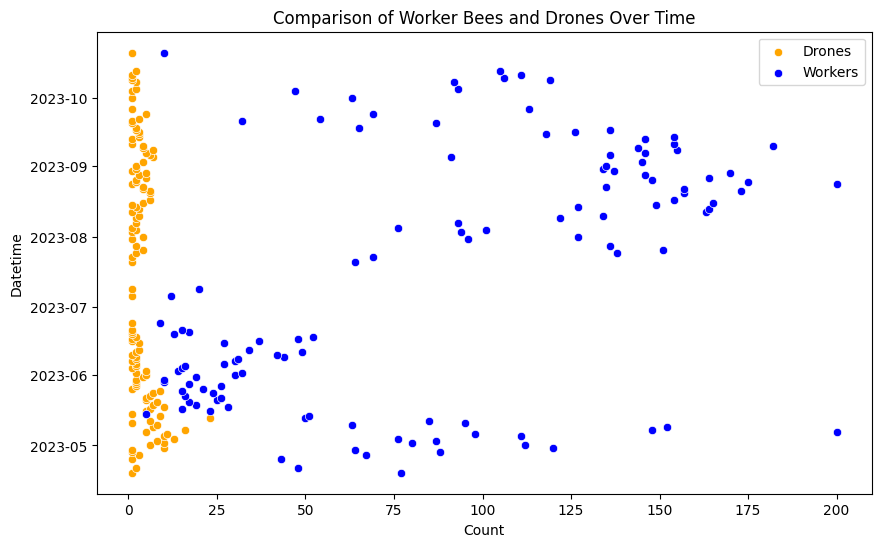

In [12]:
# Assuming 'daily_data' is your DataFrame with 'datetime' as the index
# If 'datetime' is not the index, you can set it using daily_data.set_index('datetime', inplace=True)

# Replace '0' values with NaN in the 'drones' column
daily_data['drones'].replace(0, np.nan, inplace=True)

# Convert 'drones' column to integers and drop rows with null values in 'drones'
daily_data['drones'] = daily_data['drones']
daily_data.dropna(subset=['drones'], inplace=True)

# Check if there are still null values in 'drones'
print("Number of null values in 'drones':", daily_data['drones'].isnull().sum())

# Create a scatter plot to compare the number of worker bees and drones
plt.figure(figsize=(10, 6))

# Scatter plot for 'drones'
sns.scatterplot(data=daily_data, x='drones', y='datetime', color='orange', label='Drones')

# Scatter plot for 'workers'
sns.scatterplot(data=daily_data, x='workers', y='datetime', color='blue', label='Workers')

# Add title and labels for better clarity
plt.title('Comparison of Worker Bees and Drones Over Time')
plt.xlabel('Count')
plt.ylabel('Datetime')

# Show the plot
plt.show()


In [13]:
# dataset['workers'].plot(color="orange", figsize= (12,6))
# plt.xlabel('time - days')
# plt.ylabel('total amount of worker bees')
# plt.title('Plotting the total amount of worker (female) bees')
# plt.show()
# print("Not stationary")

# dataset['drones'].plot(color="orange", figsize= (12,6))
# plt.xlabel('time - days')
# plt.ylabel('total amount of drone bees')
# plt.title('Plotting the amount of drone (male) bees')
# plt.show()
# print("Not stationary")

# dataset['total'].plot(color="orange", figsize= (12,6))
# plt.xlabel('time - days')
# plt.ylabel('total amount of bees')
# plt.title('Plotting the total amount of bees')
# plt.show()
# print("Not stationary")



![alt text](difference.png "Title")


Deeper analysis



In [14]:
# Assuming df is your DataFrame
daily_data = daily_data.iloc[7:]

# Reset the index if needed
# daily_data.reset_index(drop=True, inplace=True)
daily_data.head(20)

,temperature,humidity,filesize,workers,drones,weight_change
datetime,,,,,,
2023-05-01,93.508571,50.028571,221525149,112,6.0,0.000000
2023-05-02,94.100000,48.666667,191686176,80,10.0,0.000000
2023-05-03,95.540000,46.142857,222663595,87,8.0,0.000000
2023-05-04,95.330000,47.100000,188573098,76,13.0,0.001069
2023-05-05,94.948571,45.900000,218797138,111,10.0,0.000000
2023-05-06,94.537143,48.342857,233368016,98,11.0,0.000000
2023-05-07,94.768571,47.642857,310946102,200,5.0,0.000000
2023-05-08,93.560000,58.757143,235808588,148,16.0,0.000000
2023-05-09,89.805714,69.000000,249409622,152,7.0,0.000000


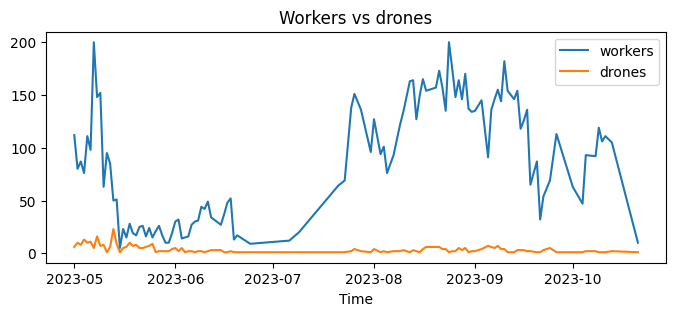

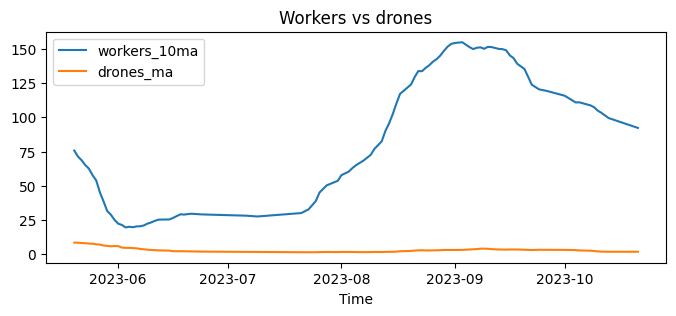

In [15]:
# Ploting the data
plt.figure(figsize=(8,3))
plt.plot(daily_data.index, daily_data["workers"], label="workers")
plt.plot(daily_data.index, daily_data["drones"], label="drones")
plt.legend()
plt.title("Workers vs drones")
plt.xlabel("Time")
plt.show()

# Plot rolling window
window = 20
plt.figure(figsize=(8,3))
plt.plot(daily_data.index, daily_data["workers"].rolling(window).mean(), label="workers_10ma")
plt.plot(daily_data.index, daily_data["drones"].rolling(window).mean(), label="drones_ma")
plt.legend()
plt.title("Workers vs drones")
plt.xlabel("Time")
plt.show()

In [16]:
#daily_data.drop(columns='weight_change', inplace=True)

#mean_ratio = daily_data['ratio'].mean()
#daily_data['ratio'].fillna(mean_ratio, inplace=True)
daily_data.head(10)


,temperature,humidity,filesize,workers,drones,weight_change
datetime,,,,,,
2023-05-01,93.508571,50.028571,221525149,112,6.0,0.000000
2023-05-02,94.100000,48.666667,191686176,80,10.0,0.000000
2023-05-03,95.540000,46.142857,222663595,87,8.0,0.000000
2023-05-04,95.330000,47.100000,188573098,76,13.0,0.001069
2023-05-05,94.948571,45.900000,218797138,111,10.0,0.000000
2023-05-06,94.537143,48.342857,233368016,98,11.0,0.000000
2023-05-07,94.768571,47.642857,310946102,200,5.0,0.000000
2023-05-08,93.560000,58.757143,235808588,148,16.0,0.000000
2023-05-09,89.805714,69.000000,249409622,152,7.0,0.000000


<Axes: >

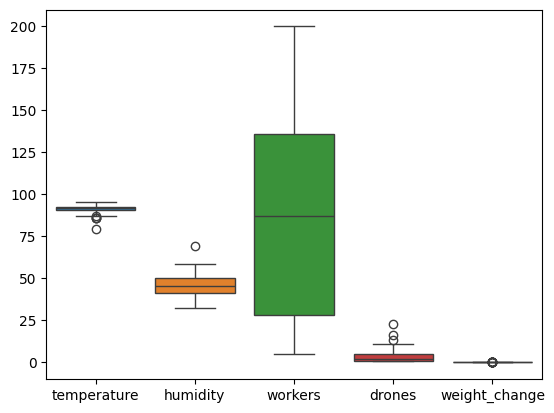

In [17]:
daily_data2 = daily_data.drop(columns='filesize',inplace=False)
sns.boxplot(daily_data2)

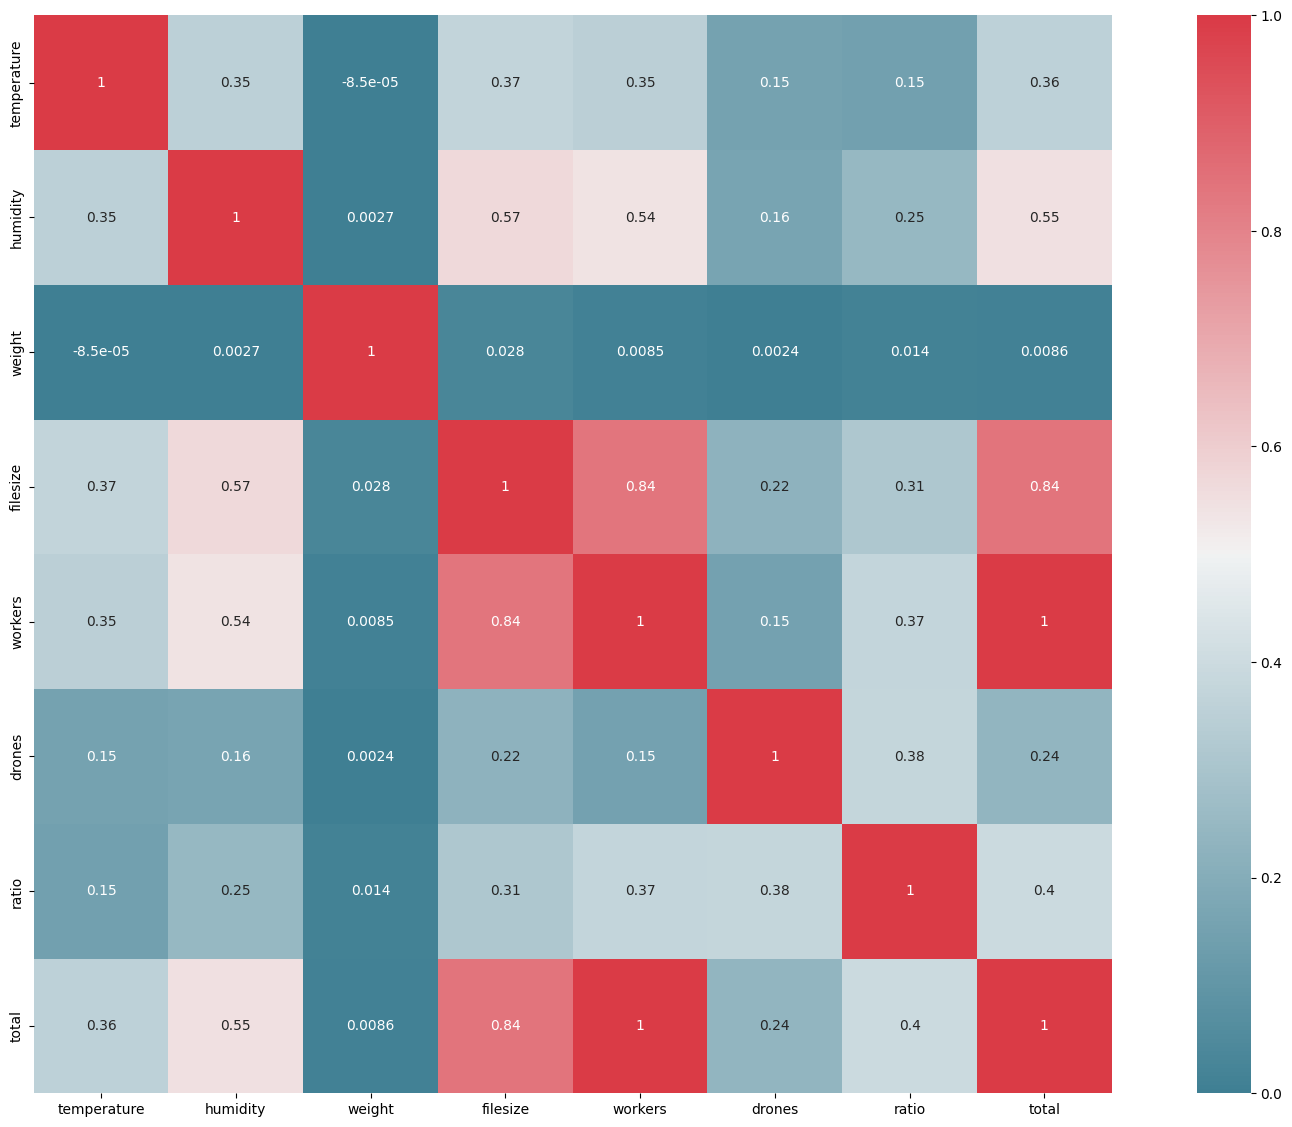

In [18]:
#heatmap
daily_data.corr()

f, ax = plt.subplots(figsize=(22, 14))
corr = dataset.corr()
sns.heatmap(corr, mask=np.zeros_like(corr, dtype=bool), cmap=sns.diverging_palette(220, 10, as_cmap=True),
            square=True, ax=ax,annot=True)
plt.show()

In [19]:
#tweaking the dataset for the model
daily_data.drop(columns=['drones', 'weight_change', 'temperature'], inplace=True)

In [20]:
daily_data.head(10)

,humidity,filesize,workers
datetime,,,
2023-05-01,50.028571,221525149,112
2023-05-02,48.666667,191686176,80
2023-05-03,46.142857,222663595,87
2023-05-04,47.100000,188573098,76
2023-05-05,45.900000,218797138,111
2023-05-06,48.342857,233368016,98
2023-05-07,47.642857,310946102,200
2023-05-08,58.757143,235808588,148
2023-05-09,69.000000,249409622,152


In [21]:
# from sklearn.model_selection import train_test_split
# y = daily_data['workers']
# X = daily_data.drop(columns=['workers'])

# X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)


In [22]:
# from sklearn.ensemble import RandomForestRegressor
# from sklearn.metrics import mean_squared_error




# model = RandomForestRegressor(n_estimators=100, random_state=42)
# model.fit(X_train, y_train)
# y_pred = model.predict(X_test)
# mse = mean_squared_error(y_test, y_pred)

# print(mse)


In [24]:
# print("\n")
# print(X_test[:5])
# print(y_pred[:5],'\n')
# print(y_test[:5])
# print(mse)

# Support vectors | boosting algorithms
#random forest variable analysis

In [25]:
# # Assuming daily_data is already defined and contains your DataFrame

# # Check for NaN values in daily_data
# has_nan_values = X_test.isna().any().any()

# if has_nan_values:
#     print("There are NaN values in the daily_data DataFrame.")
# else:
#     print("There are no NaN values in the daily_data DataFrame.")

# LOGISTIC REGRESSION L1-L2

In [26]:
dataset = pd.read_csv('bee_data.csv')
dataset.head(10)

,datetime,temperature,humidity,weight,filesize,workers,drones,ratio,total
0,2023-04-17 10:00:00,88.70,47.0,0.0,30960338,8,0,0.0,8
1,2023-04-17 12:00:00,88.70,49.8,0.0,30199021,18,0,0.0,18
2,2023-04-17 14:00:00,87.98,39.6,0.0,6214516,2,0,0.0,2
3,2023-04-17 16:00:00,87.56,43.0,0.0,61036,0,0,0.0,0
4,2023-04-17 18:00:00,87.14,46.4,0.0,59631,0,0,0.0,0
5,2023-04-17 20:00:00,86.72,49.8,0.0,60209,0,0,0.0,0
6,2023-04-18 08:00:00,89.96,45.3,0.0,57249447,18,0,0.0,18
7,2023-04-18 10:00:00,91.76,49.0,0.0,62443542,19,0,0.0,19
8,2023-04-18 12:00:00,92.39,47.5,0.0,41671100,7,0,0.0,7
9,2023-04-18 14:00:00,93.02,46.0,0.0,20154931,9,0,0.0,9


In [27]:
# 2 hourly --> daily

# Read the dataset from the CSV file
dataset = pd.read_csv('bee_data.csv', index_col='datetime')

# Convert the 'datetime' column to datetime type if it's not already
dataset.index = pd.to_datetime(dataset.index)

# Resample to daily frequency and aggregate using sum
daily_data = dataset.resample('D').sum()

aggregation = {
    'temperature': 'mean', # Take mean instead of sum
    'humidity': 'mean',  # Take mean instead of sum
    'weight': 'last', # take last weight change of the day which is kind of like taking the sum but without getting NaN values
    'filesize': 'sum',
    'workers': 'sum',
    'drones': 'sum',
}

# Resample to daily frequency and aggregate with different functions
daily_data = dataset.resample('D').agg(aggregation)
#daily_data['weight_change'] = dataset['weight'] #readding weight
daily_data['weight_change'] = daily_data['weight']
daily_data.drop(columns=['weight'], inplace=True)
# Use the cumulative sum of weight for a more accurate result then just using sum:
#daily_data['weight_cumsum'] = daily_data['weight'].cumsum()


print("Original DataFrame:")
print(dataset.head(2))
print("\nDaily aggregated DataFrame:")
print(daily_data.head(2))


Original DataFrame:
                     temperature  humidity  weight  filesize  workers  drones  \
datetime                                                                        
2023-04-17 10:00:00         88.7      47.0     0.0  30960338        8       0   
2023-04-17 12:00:00         88.7      49.8     0.0  30199021       18       0   

                     ratio  total  
datetime                           
2023-04-17 10:00:00    0.0      8  
2023-04-17 12:00:00    0.0     18  

Daily aggregated DataFrame:
            temperature   humidity   filesize  workers  drones  weight_change
datetime                                                                     
2023-04-17      87.8000  45.933333   67554751       28       0            0.0
2023-04-18      91.7825  46.950000  181519020       53       0            0.0


In [28]:
daily_data.head(10)



,temperature,humidity,filesize,workers,drones,weight_change
datetime,,,,,,
2023-04-17,87.800000,45.933333,67554751,28,0,0.000000
2023-04-18,91.782500,46.950000,181519020,53,0,0.000000
2023-04-19,91.991429,51.442857,249608995,77,1,0.000000
2023-04-20,90.114286,49.871429,67360526,31,0,0.002250
2023-04-21,86.945000,46.237500,108699349,48,2,0.000000
2023-04-22,90.885714,49.885714,138937170,66,0,0.000111
2023-04-23,91.297143,49.335714,128830793,58,0,0.002333
2023-04-24,89.188571,46.242857,97215486,42,0,0.000000
2023-04-25,87.517143,45.314286,121026015,43,1,0.000000


In [29]:
missing_values_count = daily_data.isnull().sum()
print('The amount of missing values \n'+ str(missing_values_count))
print("There are no missing values.")

The amount of missing values 
temperature      0
humidity         0
filesize         0
workers          0
drones           0
weight_change    0
dtype: int64
There are no missing values.


In [30]:
# sns.pairplot(data=daily_data)

In [31]:

import numpy as np

# Splitting the dataset into features and target
y = daily_data['workers'].values
X = daily_data.drop('workers', axis=1).values

# Splitting the dataset into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Feature scaling
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train a Linear Regression model
lregmodel = LinearRegression()
lregmodel.fit(X_train_scaled, y_train)

# Display coefficients and intercept
print("Coefficients:")
print(lregmodel.coef_)
print("\nIntercept:")
print(lregmodel.intercept_)



Coefficients:
[  5.90970883  14.54666839 211.89557248 -23.43099725  -3.93700301]

Intercept:
-10.1241236724901


In [32]:
daily_data.head()

,temperature,humidity,filesize,workers,drones,weight_change
datetime,,,,,,
2023-04-17,87.800000,45.933333,67554751,28,0,0.00000
2023-04-18,91.782500,46.950000,181519020,53,0,0.00000
2023-04-19,91.991429,51.442857,249608995,77,1,0.00000
2023-04-20,90.114286,49.871429,67360526,31,0,0.00225
2023-04-21,86.945000,46.237500,108699349,48,2,0.00000


In [33]:
y_predicted = lregmodel.predict(X_test)

## Mean Absolute Error
from sklearn.metrics import mean_absolute_error

MAE = mean_absolute_error(y_test,y_predicted)
print('MAE = ',MAE)

## Mean Squared Error
from sklearn.metrics import mean_squared_error

MSE = mean_squared_error(y_test,y_predicted)
print('MSE = ',MSE)

## coefficient of determination = r2 score
from sklearn.metrics import r2_score

r2 = r2_score(y_test,y_predicted)

print('r2 score = ',r2)

### alternative for r2 score
r2 = lregmodel.score(X_test,y_test)
print('r2 score = ', r2)

MAE =  32189661361.514275
MSE =  1.4431351596450964e+21
r2 score =  -5.559139843149778e+17
r2 score =  -5.559139843149778e+17


In [34]:
# Splitting the dataset into a train- and testset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0) #80% training, 20% test

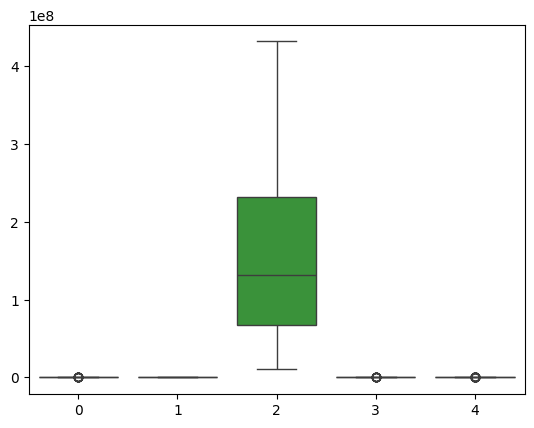

Needs scaling


In [35]:
# Visualise your features with a boxplot

sns.boxplot(data = X_train)
plt.show()
print("Needs scaling")

In [36]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(X_train)

X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)


In [37]:
from sklearn.linear_model import LinearRegression
lregmodel = LinearRegression()
lregmodel.fit(X_train, y_train)

print("Coefficients:")
print(lregmodel.coef_)
print("\nIntercept:")
print(lregmodel.intercept_)

Coefficients:
[  5.90970883  14.54666839 211.89557248 -23.43099725  -3.93700301]

Intercept:
-10.1241236724901


In [38]:

# Model optimization
# Adding higher order features



# Generate higher order features
degree = 3

poly = PolynomialFeatures(degree)
poly.fit(X_train)
X_train_poly = poly.transform(X_train)
X_test_poly = poly.transform(X_test)
print('dimension of X_train_poly: ',X_train_poly.shape)
print('dimension of X_test_poly: ',X_test_poly.shape)

print(' ')

# L2 regularization: Ridge regression
lregmodel_poly_r = Ridge(alpha=400,tol=0.0001,fit_intercept=True)
lregmodel_poly_r.fit(X_train_poly,y_train)

print('R2 score of L2 - test set: ',lregmodel_poly_r.score(X_test_poly,y_test))
# R2 -score via L2 on the traing set
print('R2 score of L2 - training set: ',lregmodel_poly_r.score(X_train_poly,y_train))

print('')


# L1 regularization: Lasso regression
lregmodel_poly = Lasso(alpha=3,tol=0.0001,fit_intercept=True)
lregmodel_poly.fit(X_train_poly,y_train)      
  
      
print('R2 score of L1 - test set: ',lregmodel_poly.score(X_test_poly,y_test))
  
# R2 -score via L1 on trainingset
print('R2 score of L1 - training set: ',lregmodel_poly.score(X_train_poly,y_train))    
print("The score is pretty okay!")


dimension of X_train_poly:  (156, 56)
dimension of X_test_poly:  (39, 56)
 
R2 score of L2 - test set:  0.3219393678708876
R2 score of L2 - training set:  0.2781935485595698

R2 score of L1 - test set:  0.8359582867610607
R2 score of L1 - training set:  0.8285566138974617
The score is pretty okay!


In [39]:
# Transform testing data with polynomial features
X_test_poly = poly.transform(X_test)

# Now you can use X_test_poly for prediction
y_pred = lregmodel_poly.predict(X_test_poly)
print(y_pred[:5],'\n')
print(y_test[:5])
MSE = mean_squared_error(y_test,y_pred)
print(MSE)



[32.30552088 80.32587692 51.94021616 79.31293999 80.1915322 ] 

[ 20  64  17 103  93]
425.8471107094862


# Model 2 - Random forests

In [40]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold, GroupKFold
from sklearn.metrics import mean_squared_error

In [41]:
# 2 hourly --> daily

# Read the dataset from the CSV file
dataset = pd.read_csv('bee_data.csv', index_col='datetime')

# Convert the 'datetime' column to datetime type if it's not already
dataset.index = pd.to_datetime(dataset.index)

# Resample to daily frequency and aggregate using sum
daily_data_m2 = dataset.resample('D').sum()

aggregation = {
    'temperature': 'mean', # Take mean instead of sum
    'humidity': 'mean',  # Take mean instead of sum
    'weight': 'last', # take last weight change of the day which is kind of like taking the sum but without getting NaN values
    'filesize': 'sum',
    'workers': 'sum',
    'drones': 'sum',
}

# Resample to daily frequency and aggregate with different functions
daily_data = dataset.resample('D').agg(aggregation)
#daily_data['weight_change'] = dataset['weight'] #readding weight
daily_data['weight_change'] = daily_data['weight']
daily_data.drop(columns=['weight'], inplace=True)
# Use the cumulative sum of weight for a more accurate result then just using sum:
#daily_data['weight_cumsum'] = daily_data['weight'].cumsum()


print("Original DataFrame:")
print(dataset.head(2))
print("\nDaily aggregated DataFrame:")
print(daily_data.head(2))


Original DataFrame:
                     temperature  humidity  weight  filesize  workers  drones  \
datetime                                                                        
2023-04-17 10:00:00         88.7      47.0     0.0  30960338        8       0   
2023-04-17 12:00:00         88.7      49.8     0.0  30199021       18       0   

                     ratio  total  
datetime                           
2023-04-17 10:00:00    0.0      8  
2023-04-17 12:00:00    0.0     18  

Daily aggregated DataFrame:
            temperature   humidity   filesize  workers  drones  weight_change
datetime                                                                     
2023-04-17      87.8000  45.933333   67554751       28       0            0.0
2023-04-18      91.7825  46.950000  181519020       53       0            0.0


In [42]:
X = daily_data_m2.loc[:, ['temperature', 'humidity', 'weight', 'filesize']]  # Predictors
y = daily_data_m2.loc[:, ['total']] # Target

In [43]:
daily_data_m2.shape
daily_data_m2.to_excel('graphs_2.xlsx', index=True)
daily_data_m2.to_csv('graphs.csv', index=True)

In [44]:
def split_and_add_group_column(dataset, group_size):
    """
    Split a dataset into groups and add an extra column with the group number.

    Parameters:
        dataset (pandas.DataFrame): DataFrame containing the dataset.
        group_size (int): Size of each group.

    Returns:
        pandas.DataFrame: DataFrame with an additional column 'Group' indicating the group number.
    """
    # Calculate the total number of groups
    num_groups = len(dataset) // group_size

    # Create a list to store the group numbers
    group_numbers = []
    for group_num in range(num_groups):
        group_numbers.extend([group_num + 1] * group_size)

    # Add the group numbers as a new column to the dataset
    dataset_with_groups = dataset.assign(Group=group_numbers[:len(dataset)])

    return dataset_with_groups

In [45]:
grouped_daily_data_m2 = split_and_add_group_column(daily_data_m2, 5)
grouped_daily_data_m2.head(20)

,temperature,humidity,weight,filesize,workers,drones,ratio,total,Group
datetime,,,,,,,,,
2023-04-17,526.80,275.60,0.000000,67554751,28,0,0.00,28,1
2023-04-18,367.13,187.80,0.000000,181519020,53,0,0.00,53,1
2023-04-19,643.94,360.10,0.001240,249608995,77,1,20.00,78,1
2023-04-20,630.80,349.10,0.003027,67360526,31,0,0.00,31,1
2023-04-21,347.78,184.95,0.002333,108699349,48,2,15.00,50,1
2023-04-22,636.20,349.20,0.000111,138937170,66,0,0.00,66,2
2023-04-23,639.08,345.35,0.003938,128830793,58,0,0.00,58,2
2023-04-24,624.32,323.70,0.000000,97215486,42,0,0.00,42,2
2023-04-25,612.62,317.20,0.005615,121026015,43,1,15.00,44,2


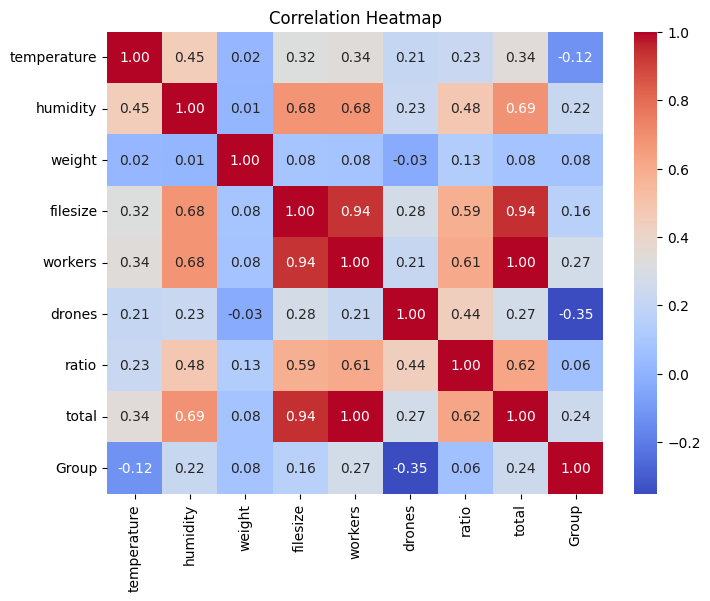

Aggregating the daily set to daily increases the correlation of all variables slightly
5-15%


In [46]:
correlation_matrix = grouped_daily_data_m2.corr()
correlation_matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

print("Aggregating the daily set to daily increases the correlation of all variables slightly")
print("5-15%")

In [47]:
#Random forests using grouped data:
seed=1234
model = RandomForestRegressor(n_estimators=100, random_state=seed)
groups = grouped_daily_data_m2['Group']

# Stratified 5-fold cross-validation
gkf = GroupKFold(n_splits=10)
scores = cross_val_score(model, X, y, groups=groups, cv=gkf)
print('Cross-validation scores:', scores)
print('Average cross-validation score:', np.mean(scores))
print("The avg cross valid score is also slightly higher")

c:\Users\Elliot\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\Elliot\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\Elliot\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\Elliot\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1152: DataCon

Cross-validation scores: [0.91056825 0.9693888  0.92045303 0.92051683 0.93880062 0.87675057
 0.58224754 0.32664633 0.7786818  0.88496309]
Average cross-validation score: 0.8109016859898464
The avg cross valid score is also slightly higher


In [48]:
gkf.split(X, y, groups=groups)
parameter_importances = []

for train_index, test_index in gkf.split(X, y, groups=groups):

    X_train, X_test = X.iloc[train_index,:], X.iloc[test_index,:]
    y_train, y_test = y.iloc[train_index,:], y.iloc[test_index,:]
    
    model = RandomForestRegressor(n_estimators=100, random_state=seed)
    model.fit(X_train, y_train)
    fold_importances = [est.feature_importances_ for est in model.estimators_]
    parameter_importances.append(fold_importances)

c:\Users\Elliot\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\Elliot\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\Elliot\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1152: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\Elliot\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1152: DataCon

In [49]:
pd.DataFrame([x[0] for x in parameter_importances], columns=X.columns).mean()

temperature    0.025837
humidity       0.032547
weight         0.021236
filesize       0.920379
dtype: float64

In [50]:
y_predicted = model.predict(X_test)

## Mean Absolute Error


MAE = mean_absolute_error(y_test,y_predicted)
print('MAE = ',MAE)

## Mean Squared Error


MSE = mean_squared_error(y_test,y_predicted)
print('MSE = ',MSE)

## coefficient of determination = r2 score


r2 = r2_score(y_test,y_predicted)

print('r2 score = ',r2)

### alternative for r2 score
r2 = model.score(X_test,y_test)
print('r2 score = ', r2)

mse = mean_squared_error(y_test, y_predicted)
print("\n")
print(X_test[:5])
print(y_predicted[:5],'\n')
print(y_test[:5])
print(mse)
#remove outliers
#remove weight


MAE =  15.034
MSE =  351.5169933333334
r2 score =  0.8849630947013222
r2 score =  0.8849630947013222


            temperature  humidity    weight  filesize
datetime                                             
2023-05-27       631.70     271.5  0.009062  96229476
2023-05-28       637.28     270.1  0.000036  72136387
2023-05-29       613.70     226.7  0.000036  46938887
2023-05-30       603.08     239.6  0.003321  53604264
2023-05-31       611.18     266.4  0.000125  84458602
[33.26 26.02  5.01  8.05 31.81] 

            total
datetime         
2023-05-27     28
2023-05-28     19
2023-05-29     12
2023-05-30     12
2023-05-31     23
351.5169933333334


In [52]:
grouped_daily_data_m2.head(10)

,temperature,humidity,weight,filesize,workers,drones,ratio,total,Group
datetime,,,,,,,,,
2023-04-17,526.80,275.60,0.000000,67554751,28,0,0.0,28,1
2023-04-18,367.13,187.80,0.000000,181519020,53,0,0.0,53,1
2023-04-19,643.94,360.10,0.001240,249608995,77,1,20.0,78,1
2023-04-20,630.80,349.10,0.003027,67360526,31,0,0.0,31,1
2023-04-21,347.78,184.95,0.002333,108699349,48,2,15.0,50,1
2023-04-22,636.20,349.20,0.000111,138937170,66,0,0.0,66,2
2023-04-23,639.08,345.35,0.003938,128830793,58,0,0.0,58,2
2023-04-24,624.32,323.70,0.000000,97215486,42,0,0.0,42,2
2023-04-25,612.62,317.20,0.005615,121026015,43,1,15.0,44,2
